In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Đọc file Position_Salaries.csv
dataset = pd.read_csv("Position_Salaries.csv")

# Tách biến đầu vào X (Cột Level - index 1)
# Dùng 1:2 để giữ X ở dạng ma trận 2D shape (10, 1)
X = dataset.iloc[:, 1:2].values

# Tách nhãn y (Cột Salary - index 2)
y = dataset.iloc[:, 2].values

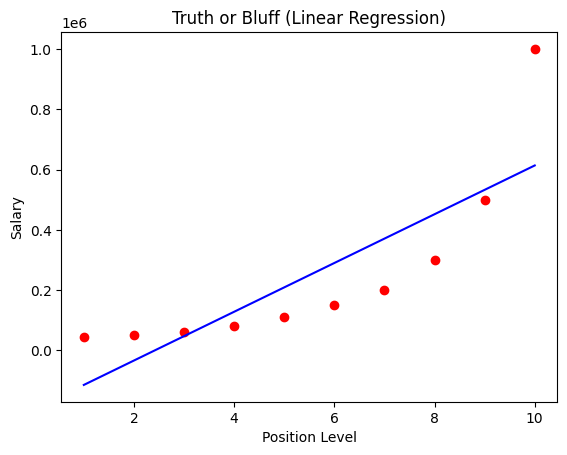

In [ ]:
from sklearn.linear_model import LinearRegression

# Huấn luyện đường thẳng bậc 1
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# Vẽ thử nghiệm thu
plt.scatter(X, y, color='red')
plt.plot(X, lin_reg.predict(X), color='blue')
plt.title("Truth or Bluff (Linear Regression)")
plt.xlabel("Position Level")
plt.ylabel("Salary")
plt.show()

**Đu má, chỗ này mô hình học dốt vãi .Mức lương của CEO level 10 đoán trật lất**

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Khởi tạo máy tạo đặc trưng đa thức với bậc degree = 4
poly_reg = PolynomialFeatures(degree=4)

# Bấm nút .fit_transform() để tạo ra các cột x^0, x^1, x^2, x^3, x^4
X_poly = poly_reg.fit_transform(X)

In [ ]:
# Tạo mô hình hồi quy mới
poly_lin_reg = LinearRegression()

# Cho máy học trên ma trận đã nhân bậc lũy thừa
poly_lin_reg.fit(X_poly, y)

LinearRegression()

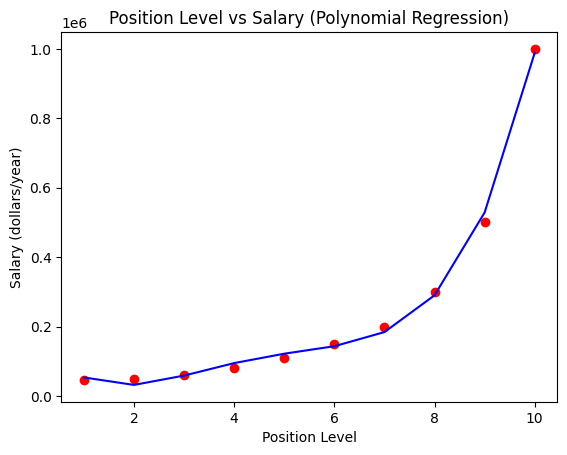

In [ ]:
# Dự đoán dựa trên X_poly
y_poly_pred = poly_lin_reg.predict(X_poly)

# Vẽ đồ thị
plt.scatter(X, y, color='red')  # Chấm điểm thực tế
plt.plot(X, y_poly_pred, color='blue')  # Đường cong nối các điểm dự đoán
plt.title("Position Level vs Salary (Polynomial Regression)")
plt.xlabel("Position Level")
plt.ylabel("Salary (dollars/year)")
plt.show()

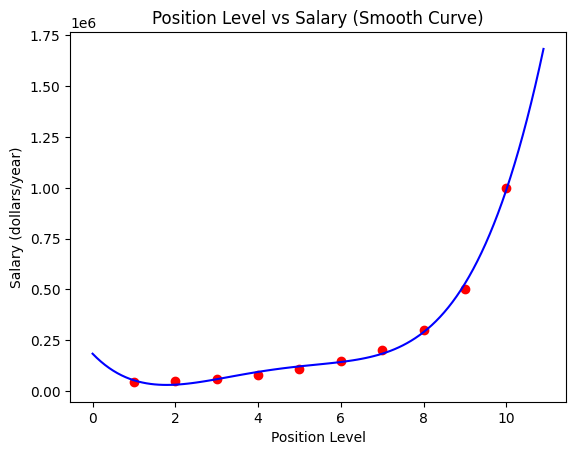

In [ ]:
# Tạo một dải điểm dày đặc từ 0 đến 10, bước nhảy 0.1
# [0.0, 0.1, 0.2, 0.3, ..., 10.0]
X_dummy = np.arange(0, 11, 0.1).reshape(-1, 1)

# Biến hình X_dummy sang bậc 4 rồi mới đoán
X_dummy_poly = poly_reg.fit_transform(X_dummy)
y_dummy_pred = poly_lin_reg.predict(X_dummy_poly)

# Vẽ đường cong mượt mà tuyệt đối
plt.scatter(X, y, color='red')
plt.plot(X_dummy, y_dummy_pred, color='blue')
plt.title("Position Level vs Salary (Smooth Curve)")
plt.xlabel("Position Level")
plt.ylabel("Salary (dollars/year)")
plt.show()

In [ ]:
# Đưa giá trị 6.5 qua cỗ máy biến hình bậc 4 rồi mới predict
luong_du_doan = poly_lin_reg.predict(poly_reg.fit_transform([[6.5]]))
print(f"Mức lương hợp lý cho Level 6.5: {luong_du_doan[0]:,.2f} USD")

Mức lương hợp lý cho Level 6.5: 158,862.45 USD
